In [41]:
from pathlib import Path
import pickle
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

# Matched to the earlier evaluator notebook.
legend_properties = {'weight': 'bold'}
nus_blue = '#003D7C'
nus_orange = '#EF7C00'
morandi_blue = '#046586'
morandi_green = '#28A9A1'
morandi_yellow = '#C9A77C'
morandi_orange = '#F4A016'
morandi_pink = '#F6BBC6'
morandi_red = '#E71F19'
morandi_purple = '#B08BEB'
shallow_grey = '#D3D4D3'

K_colors = [morandi_blue, morandi_orange, morandi_green, morandi_purple,
            morandi_red, morandi_yellow, '#555555', '#B75F91']


def safe_nanmean(values, axis=None):
    """Ignore structurally undefined adoption values, retaining all-NaN as NaN."""
    with warnings.catch_warnings():
        warnings.simplefilter('ignore', category=RuntimeWarning)
        return np.nanmean(values, axis=axis)


In [42]:
# =========================
# Experiment configuration — same as Visibility_maturity.py
# =========================
N = 18
agent_num = 100
knowledge_breadth = 12
landscape_iteration = 600  # Documentation only; averages were already computed upstream.
solver_reset_num = 10  # Documentation only; averages were already computed upstream.
search_iteration = 300
visibility_interval = 10
K_list = list(range(9, N))
maturity_threshold_list = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.725, 0.75, 0.775, 0.8, 0.825, 0.85, 0.875, 0.9]
# Major tick marks are limited to the evaluated range (0.1 to 0.9 here).
maturity_axis_ticks = np.round(np.arange(
    np.floor(max(maturity_threshold_list) * 10) / 10,
    np.ceil(min(maturity_threshold_list) * 10) / 10 - 0.05, -0.1), 1)
maturity_plot_xlim = (max(maturity_threshold_list) + 0.05,
                      min(maturity_threshold_list) - 0.05)

# imshow uses integer column positions rather than numeric threshold coordinates.
# Label only threshold values that actually exist in maturity_threshold_list.
heatmap_tick_positions = [i for i, threshold in enumerate(maturity_threshold_list)
                          if np.any(np.isclose(threshold, maturity_axis_ticks))]
heatmap_tick_labels = [f'{maturity_threshold_list[i]:.1f}' for i in heatmap_tick_positions]
uniform_sharing_prob = 1.0  # Held constant; maturity_threshold is the focal parameter.

# Change this to the folder containing your maturity pickle outputs, if auto-detection fails.
result_folder = "/Volumes/T7/data/gst-1010-26/ISR_Visibility_5/Maturity"

strict_loading = True  # Set False to view partial results from an unfinished run.

candidate_folders = [Path.cwd(), Path.cwd() / 'Maturity', Path.cwd() / 'Results',
                     Path.cwd() / 'results', Path.cwd() / 'output', Path.cwd() / 'data']
expected_example = (f'maturity_threshold_{maturity_threshold_list[0]}'
                    f'_breakthrough_rank_across_K_size_{agent_num}')

if result_folder is None:
    result_folder = next((folder for folder in candidate_folders
                          if (folder / expected_example).is_file()), Path.cwd())
result_folder = Path(result_folder).expanduser()
if not result_folder.is_dir():
    raise FileNotFoundError(f'Result folder not found: {result_folder}. Please update result_folder.')
figure_folder = result_folder / 'maturity_threshold_figures'
figure_folder.mkdir(exist_ok=True)

print('Result folder:', result_folder)
print('Output folder:', figure_folder)
print('Example expected file:', expected_example)
print('Folder exists:', result_folder.exists())

Result folder: /Volumes/T7/data/gst-1010-26/ISR_Visibility_5/Maturity
Output folder: /Volumes/T7/data/gst-1010-26/ISR_Visibility_5/Maturity/maturity_threshold_figures
Example expected file: maturity_threshold_0.1_breakthrough_rank_across_K_size_100
Folder exists: True


## 2. Load and validate the six outcome families

Files use the naming scheme produced by `Visibility_maturity.py`:

`maturity_threshold_{threshold}_{DV}_across_K_size_{agent_num}`

The five scalar outcomes load as arrays of shape `(threshold, K)`. The adoption-fitness trajectory loads as `(threshold, K, search period)` with **30 visibility events**. The loader validates shapes, preserves undefined outcomes as `NaN`, and reports missing or malformed files without shifting rows out of alignment.

In [43]:
scalar_dvs = [
    'breakthrough_rank',
    'breakthrough_fitness',
    'pairwise_diversity',
    'unique_solution_count',
    'adopted_solution_fitness',
]
trajectory_dv = 'adopted_solution_fitness_across_time'
expected_periods = search_iteration // visibility_interval


def result_file(threshold, dv):
    filename = (f'maturity_threshold_{threshold}_'
                f'{dv}_across_K_size_{agent_num}')
    return result_folder / filename


def load_pickle(path):
    with open(path, 'rb') as infile:
        return pickle.load(infile)


def load_maturity_threshold_results(strict=True):
    n_threshold = len(maturity_threshold_list)
    n_K = len(K_list)
    data = {dv: np.full((n_threshold, n_K), np.nan) for dv in scalar_dvs}
    data[trajectory_dv] = np.full((n_threshold, n_K, expected_periods), np.nan)
    missing_files = []
    invalid_files = []

    for i, threshold in enumerate(maturity_threshold_list):
        for dv in scalar_dvs + [trajectory_dv]:
            path = result_file(threshold, dv)
            if not path.is_file():
                missing_files.append(path.name)
                continue
            try:
                values = np.asarray(load_pickle(path), dtype=float)
            except (OSError, pickle.UnpicklingError, TypeError, ValueError) as exc:
                invalid_files.append((path.name, str(exc)))
                continue
            shape = (n_K, expected_periods) if dv == trajectory_dv else (n_K,)
            if values.shape != shape:
                invalid_files.append((path.name, f'got {values.shape}; expected {shape}'))
                continue
            data[dv][i] = values

    print(f'Files loaded: {n_threshold * 6 - len(missing_files) - len(invalid_files)} / {n_threshold * 6}')
    print('Array shapes:', {dv: value.shape for dv, value in data.items()})

    if missing_files:
        print(f'\nMissing files ({len(missing_files)}):')
        for filename in missing_files[:12]:
            print('  ', filename)
        if len(missing_files) > 12:
            print('  ...')
    if invalid_files:
        print(f'\nInvalid files ({len(invalid_files)}):')
        for name, issue in invalid_files[:12]:
            print('  ', name, ':', issue)

    if strict and (missing_files or invalid_files):
        raise FileNotFoundError(
            'Missing/invalid maturity-threshold results. Edit result_folder, agent_num, '
            'the threshold grid, or set strict_loading=False for incomplete runs. '
            'First expected file: ' + str(result_file(maturity_threshold_list[0], 'breakthrough_rank'))
        )
    if not any(np.isfinite(data[dv]).any() for dv in scalar_dvs):
        raise FileNotFoundError('No valid scalar pickle outputs found in ' + str(result_folder))
    return data


data = load_maturity_threshold_results(strict=strict_loading)

Files loaded: 90 / 90
Array shapes: {'breakthrough_rank': (15, 9), 'breakthrough_fitness': (15, 9), 'pairwise_diversity': (15, 9), 'unique_solution_count': (15, 9), 'adopted_solution_fitness': (15, 9), 'adopted_solution_fitness_across_time': (15, 9, 30)}


In [44]:
# =========================
# Data checks and long-form details
# =========================
checks = {
    'breakthrough_rank': (1, 2 ** N),
    'breakthrough_fitness': (0, 1),
    'pairwise_diversity': (0, 1),
    'unique_solution_count': (1, agent_num),
    'adopted_solution_fitness': (0, 1),
}
for dv, (minimum, maximum) in checks.items():
    finite = data[dv][np.isfinite(data[dv])]
    outside = np.count_nonzero((finite < minimum - 1e-8) | (finite > maximum + 1e-8))
    print(f'{dv:29s} finite={finite.size:3d} / {data[dv].size:3d}; outside expected range={outside}')

# The trajectory's final cumulative mean should match the scalar adoption-quality
# measure for each (threshold, K), up to floating-point differences.
last_trajectory = data[trajectory_dv][:, :, -1]
both_defined = np.isfinite(last_trajectory) & np.isfinite(data['adopted_solution_fitness'])
if both_defined.any():
    gap = np.max(np.abs(last_trajectory[both_defined] - data['adopted_solution_fitness'][both_defined]))
    print('Max discrepancy: final trajectory vs. scalar adoption quality =', round(float(gap), 12))

rows = []
for i, threshold in enumerate(maturity_threshold_list):
    for j, K in enumerate(K_list):
        row = {'maturity_threshold': threshold, 'K': K}
        for dv in scalar_dvs:
            row[dv] = data[dv][i, j]
        rows.append(row)

detailed_results = pd.DataFrame(rows)
print('\nDetailed data preview (one observation per threshold × K):')
display(detailed_results.head(12).round(4))

breakthrough_rank             finite=135 / 135; outside expected range=0
breakthrough_fitness          finite=135 / 135; outside expected range=0
pairwise_diversity            finite=135 / 135; outside expected range=0
unique_solution_count         finite=135 / 135; outside expected range=0
adopted_solution_fitness      finite=134 / 135; outside expected range=0
Max discrepancy: final trajectory vs. scalar adoption quality = 0.0

Detailed data preview (one observation per threshold × K):


,maturity_threshold,K,breakthrough_rank,breakthrough_fitness,pairwise_diversity,unique_solution_count,adopted_solution_fitness
0,0.1,9,12.2395,0.9534,0.4378,34.8597,0.8102
1,0.1,10,17.5228,0.9438,0.4384,32.9383,0.8041
2,0.1,11,23.2485,0.9364,0.4389,31.1690,0.8001
3,0.1,12,31.3855,0.9286,0.4393,29.9892,0.7955
4,0.1,13,40.8193,0.9211,0.4375,28.7332,0.7901
5,0.1,14,54.2738,0.9123,0.4391,27.9978,0.7838
6,0.1,15,70.2028,0.9037,0.4398,27.4085,0.7779
7,0.1,16,91.7670,0.8985,0.4392,26.6905,0.7742
8,0.1,17,113.7175,0.8894,0.4400,26.2353,0.7665
9,0.2,9,12.6488,0.9523,0.4369,34.8055,0.8098


## 3. Main results: maturity threshold

The overall curves average each outcome equally across **all K values** in `K_list`. The corresponding by-K figures show heterogeneity across landscape complexity. Thresholds appear on a reversed numeric axis from **`0.9` (left) to `0.1` (right)**, moving from the most to the least restrictive *evaluated* disclosure condition. In the best-solution-rank figure, the dashed horizontal reference is the outcome at `0.9` (a **near-parallel-search** benchmark, not an exact no-visibility control). The `0.1` condition is the **least restrictive sampled threshold**, not a separate unrestricted-disclosure (`0.0`) condition.

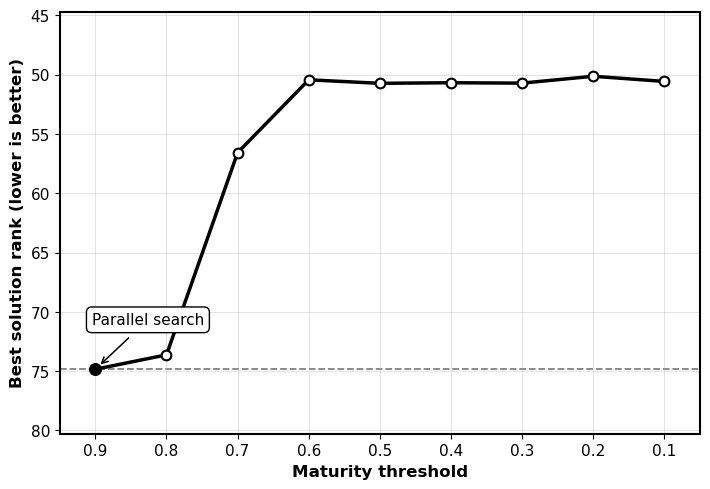

Saved: /Volumes/T7/data/gst-1010-26/ISR_Visibility_5/Maturity/maturity_threshold_figures/Breakthrough_across_maturity_threshold.png


In [64]:
# =========================
# Best solution rank across maturity threshold (average across K)
# =========================
fig, ax = plt.subplots(figsize=(7.2, 5.0))

# -------------------------
# Axis formatting
# -------------------------
for spine in ax.spines.values():
    spine.set_linewidth(1.5)
    spine.set_color("black")

ax.grid(alpha=0.5)
ax.tick_params(axis="both", labelsize=11)

# -------------------------
# Data
# -------------------------
x_all = np.asarray(maturity_threshold_list)
y_all = safe_nanmean(data["breakthrough_rank"], axis=1)

# Keep only the regular 0.1-step thresholds: 0.1, 0.2, ..., 0.9
regular_thresholds = np.round(np.arange(0.1, 1.0, 0.1), 1)
regular_mask = np.array([np.any(np.isclose(value, regular_thresholds)) for value in x_all])

x = x_all[regular_mask]
y = y_all[regular_mask]

# Identify the most restrictive benchmark point
most_restrictive_idx = int(np.argmax(x))
restrictive_x, restrictive_y = x[most_restrictive_idx], y[most_restrictive_idx]

# -------------------------
# Main curve
# -------------------------
ax.plot(
    x,
    y,
    marker="o",
    linewidth=2.5,
    markersize=7,
    color="k",
    markerfacecolor="white",
    markeredgecolor="black",
    markeredgewidth=1.5,
    zorder=2,
)

# Reverse x-axis and label only the evaluated threshold range
ax.set_xlim(0.95, 0.05)
ax.set_xticks(regular_thresholds)
ax.set_xticklabels([f"{value:.1f}" for value in regular_thresholds])
ax.margins(y=0.22)

# Highlight the most restrictive benchmark point
ax.scatter(
    restrictive_x,
    restrictive_y,
    s=70,
    color="black",
    zorder=3,
)

# -------------------------
# Horizontal benchmark line:
# performance at the most restrictive threshold
# -------------------------
ax.axhline(
    y=restrictive_y,
    color="gray",
    linestyle="--",
    linewidth=1.3,
    zorder=1,
)

# -------------------------
# Annotation-box style
# -------------------------
textbox_style = dict(
    boxstyle="round,pad=0.35",
    facecolor="white",
    edgecolor="black",
    linewidth=1.0,
)

arrow_style = dict(
    arrowstyle="->",
    linewidth=1.1,
    color="black",
    shrinkA=5,
    shrinkB=5,
)

# -------------------------
# Most restrictive case annotation
# -------------------------
ax.annotate(
    "Parallel search",
    xy=(restrictive_x, restrictive_y),
    xycoords="data",
    xytext=(0.05, 0.27),
    textcoords="axes fraction",
    ha="left",
    va="center",
    fontsize=11,
    bbox=textbox_style,
    arrowprops=arrow_style,
    annotation_clip=True,
    zorder=4,
)

# -------------------------
# Axes
# -------------------------
ax.invert_yaxis()  # Rank 1 is best; better performance appears higher.

ax.set_xlabel(
    "Maturity threshold",
    fontweight="bold",
    fontsize=12,
)

ax.set_ylabel(
    "Best solution rank (lower is better)",
    fontweight="bold",
    fontsize=12,
)

plt.tight_layout()

output_png = figure_folder / "Breakthrough_across_maturity_threshold.png"

plt.savefig(
    output_png,
    dpi=300,
    bbox_inches="tight",
    transparent=True,
)

plt.show()

print("Saved:", output_png)

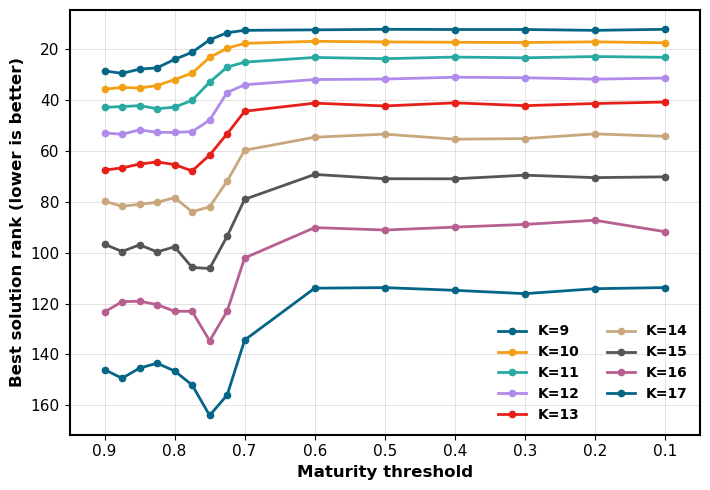

In [46]:
# Best solution rank across maturity threshold (by K).
fig, ax = plt.subplots(figsize=(7.2, 5.0))
for spine in ax.spines.values():
    spine.set_linewidth(1.5)
    spine.set_color('black')
ax.grid(alpha=0.5)
ax.tick_params(axis='both', labelsize=11)
for j, K in enumerate(K_list):
    ax.plot(maturity_threshold_list, data['breakthrough_rank'][:, j],
            marker='o', linewidth=2.0, markersize=4.5,
            label=f'K={K}', color=K_colors[j % len(K_colors)])
ax.invert_yaxis()
ax.set_xlim(*maturity_plot_xlim)
ax.set_xticks(maturity_axis_ticks)
ax.set_xticklabels([f"{value:.1f}" for value in maturity_axis_ticks])
ax.set_xlabel('Maturity threshold', fontweight='bold', fontsize=12)
ax.set_ylabel('Best solution rank (lower is better)', fontweight='bold', fontsize=12)
ax.legend(frameon=False, ncol=2, prop={'weight': 'bold', 'size': 10})
fig.tight_layout()
plt.savefig(figure_folder / 'Breakthrough_by_K_across_maturity_threshold.png', dpi=300, bbox_inches='tight', transparent=True)
plt.show()

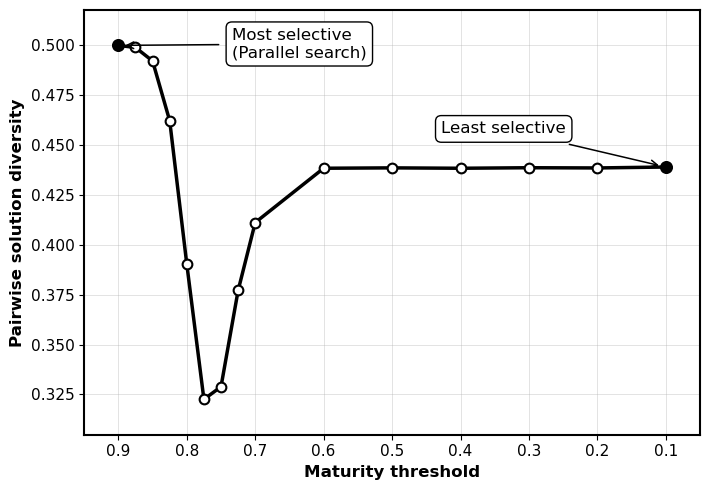

Saved: /Volumes/T7/data/gst-1010-26/ISR_Visibility_5/Maturity/maturity_threshold_figures/Pairwise_diversity_across_maturity_threshold.png


In [62]:
# =========================
# Pairwise diversity across maturity threshold (average across K)
# =========================
fig, ax = plt.subplots(figsize=(7.2, 5.0))

# -------------------------
# Axis formatting
# -------------------------
for spine in ax.spines.values():
    spine.set_linewidth(1.5)
    spine.set_color("black")

ax.grid(alpha=0.5)
ax.tick_params(axis="both", labelsize=11)

# -------------------------
# Data
# -------------------------
x = np.asarray(maturity_threshold_list)
y = safe_nanmean(data["pairwise_diversity"], axis=1)

# Identify the least and most restrictive *sampled* maturity thresholds.
least_restrictive_idx = int(np.argmin(x))
most_restrictive_idx = int(np.argmax(x))

least_x, least_y = x[least_restrictive_idx], y[least_restrictive_idx]
most_x, most_y = x[most_restrictive_idx], y[most_restrictive_idx]

# -------------------------
# Main curve
# -------------------------
ax.plot(
    x,
    y,
    marker="o",
    linewidth=2.5,
    markersize=7,
    color="k",
    markerfacecolor="white",
    markeredgecolor="black",
    markeredgewidth=1.5,
    zorder=2,
)

# Give endpoint observations some breathing room
ax.set_xlim(*maturity_plot_xlim)
ax.set_xticks(maturity_axis_ticks)
ax.set_xticklabels([f"{value:.1f}" for value in maturity_axis_ticks])
ax.margins(y=0.10)

# Highlight the two endpoint conditions
ax.scatter(
    least_x,
    least_y,
    s=70,
    color="black",
    zorder=3,
)

ax.scatter(
    most_x,
    most_y,
    s=70,
    color="black",
    zorder=3,
)

# -------------------------
# Annotation-box style
# -------------------------
textbox_style = dict(
    boxstyle="round,pad=0.35",
    facecolor="white",
    edgecolor="black",
    linewidth=1.0,
)

arrow_style = dict(
    arrowstyle="->",
    linewidth=1.1,
    color="black",
    shrinkA=5,
    shrinkB=5,
)


# -------------------------
# Near-parallel-search annotation (most restrictive threshold)
# -------------------------
ax.annotate(
    "Most selective\n(Parallel search)",
    xy=(most_x, most_y),
    xycoords="data",
    xytext=(0.24, 0.92),
    textcoords="axes fraction",
    ha="left",
    va="center",
    fontsize=12,
    bbox=textbox_style,
    arrowprops=arrow_style,
    annotation_clip=True,
    zorder=4,
)

# -------------------------
# Least restrictive evaluated threshold annotation
# -------------------------
ax.annotate(
    f"Least selective",
    xy=(least_x, least_y),
    xycoords="data",
    xytext=(0.58, 0.72),
    textcoords="axes fraction",
    ha="left",
    va="center",
    fontsize=12,
    bbox=textbox_style,
    arrowprops=arrow_style,
    annotation_clip=True,
    zorder=4,
)

# -------------------------
# Axes
# -------------------------
ax.set_xlabel(
    "Maturity threshold",
    fontweight="bold",
    fontsize=12,
)

ax.set_ylabel(
    "Pairwise solution diversity",
    fontweight="bold",
    fontsize=12,
)

plt.tight_layout()

output_png = figure_folder / "Pairwise_diversity_across_maturity_threshold.png"

plt.savefig(
    output_png,
    dpi=300,
    bbox_inches="tight",
    transparent=True,
)

plt.show()

print("Saved:", output_png)

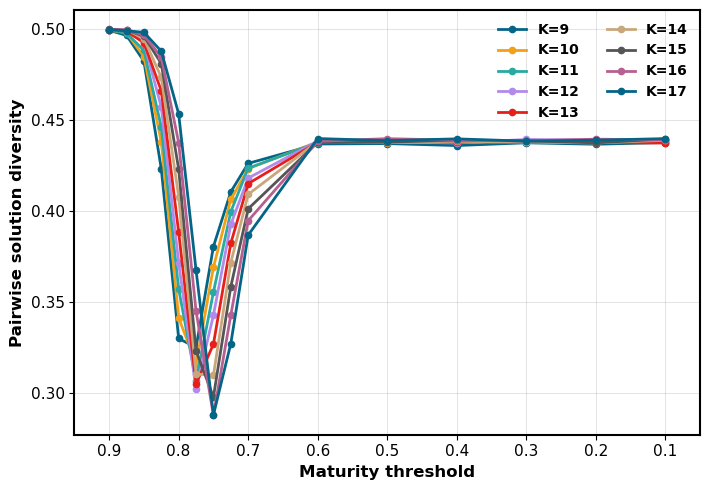

In [48]:
# Pairwise diversity across maturity threshold (by K).
fig, ax = plt.subplots(figsize=(7.2, 5.0))
for spine in ax.spines.values():
    spine.set_linewidth(1.5)
    spine.set_color('black')
ax.grid(alpha=0.5)
ax.tick_params(axis='both', labelsize=11)
for j, K in enumerate(K_list):
    ax.plot(maturity_threshold_list, data['pairwise_diversity'][:, j],
            marker='o', linewidth=2.0, markersize=4.5,
            label=f'K={K}', color=K_colors[j % len(K_colors)])
ax.set_xlim(*maturity_plot_xlim)
ax.set_xticks(maturity_axis_ticks)
ax.set_xticklabels([f"{value:.1f}" for value in maturity_axis_ticks])
ax.set_xlabel('Maturity threshold', fontweight='bold', fontsize=12)
ax.set_ylabel('Pairwise solution diversity', fontweight='bold', fontsize=12)
ax.legend(frameon=False, ncol=2, prop={'weight': 'bold', 'size': 10})
fig.tight_layout()
plt.savefig(figure_folder / 'Pairwise_diversity_by_K_across_maturity_threshold.png', dpi=300, bbox_inches='tight', transparent=True)
plt.show()

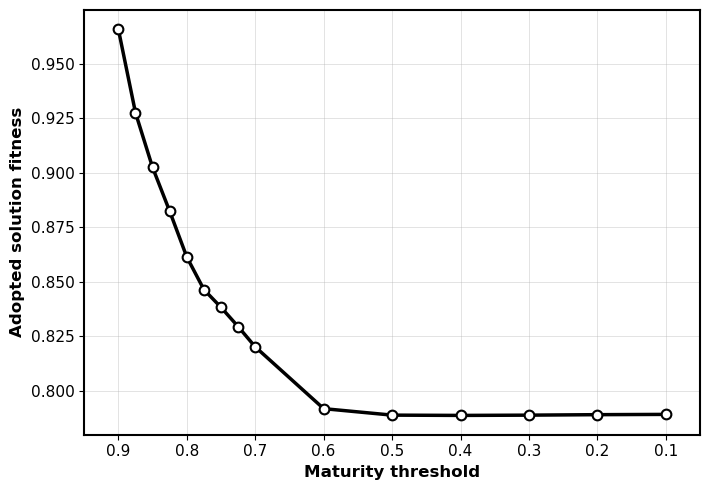

In [49]:
# Adopted solution fitness across maturity threshold (average across K).
# Undefined outcomes (no successful adoption) stay NaN and are not shown as zero.
fig, ax = plt.subplots(figsize=(7.2, 5.0))
for spine in ax.spines.values():
    spine.set_linewidth(1.5)
    spine.set_color('black')
ax.grid(alpha=0.5)
ax.tick_params(axis='both', labelsize=11)
y_adopted = safe_nanmean(data['adopted_solution_fitness'], axis=1)
ax.plot(np.asarray(maturity_threshold_list), y_adopted, marker='o', linewidth=2.5, markersize=7, color='k',
        markerfacecolor='white', markeredgecolor='black', markeredgewidth=1.5)
ax.set_xlim(*maturity_plot_xlim)
ax.set_xticks(maturity_axis_ticks)
ax.set_xticklabels([f"{value:.1f}" for value in maturity_axis_ticks])
ax.set_xlabel('Maturity threshold', fontweight='bold', fontsize=12)
ax.set_ylabel('Adopted solution fitness', fontweight='bold', fontsize=12)
fig.tight_layout()
plt.savefig(figure_folder / 'Adopted_solution_quality_across_maturity_threshold.png', dpi=300, bbox_inches='tight', transparent=True)
plt.show()

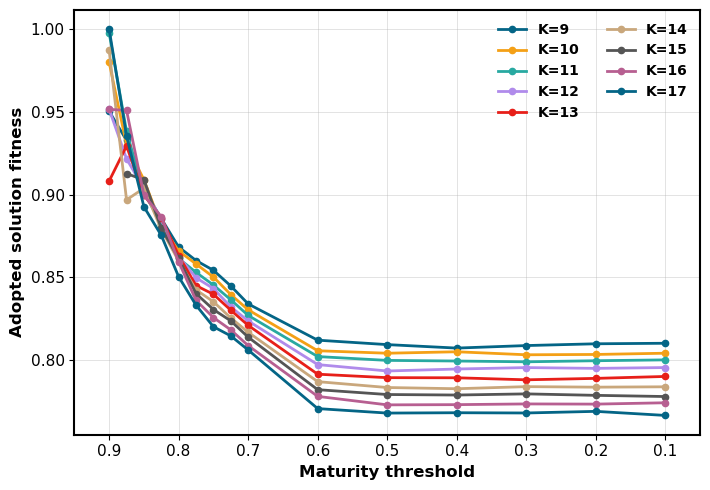

In [50]:
# Adopted solution fitness across maturity threshold (by K).
fig, ax = plt.subplots(figsize=(7.2, 5.0))
for spine in ax.spines.values():
    spine.set_linewidth(1.5)
    spine.set_color('black')
ax.grid(alpha=0.5)
ax.tick_params(axis='both', labelsize=11)
for j, K in enumerate(K_list):
    ax.plot(maturity_threshold_list, data['adopted_solution_fitness'][:, j],
            marker='o', linewidth=2.0, markersize=4.5,
            label=f'K={K}', color=K_colors[j % len(K_colors)])
ax.set_xlim(*maturity_plot_xlim)
ax.set_xticks(maturity_axis_ticks)
ax.set_xticklabels([f"{value:.1f}" for value in maturity_axis_ticks])
ax.set_xlabel('Maturity threshold', fontweight='bold', fontsize=12)
ax.set_ylabel('Adopted solution fitness', fontweight='bold', fontsize=12)
ax.legend(frameon=False, ncol=2, prop={'weight': 'bold', 'size': 10})
fig.tight_layout()
plt.savefig(figure_folder / 'Adopted_solution_fitness_by_K_across_maturity_threshold.png', dpi=300, bbox_inches='tight', transparent=True)
plt.show()

## 4. Additional outcomes

`breakthrough_fitness` is the highest final receiver-solution fitness within a repetition; `breakthrough_rank` is the best final receiver solution's rank in the landscape. These are related but distinct summary scales. `unique_solution_count` captures the number of distinct final receiver solutions, whereas **pairwise diversity** captures how different those solutions are even when uniqueness coincides.

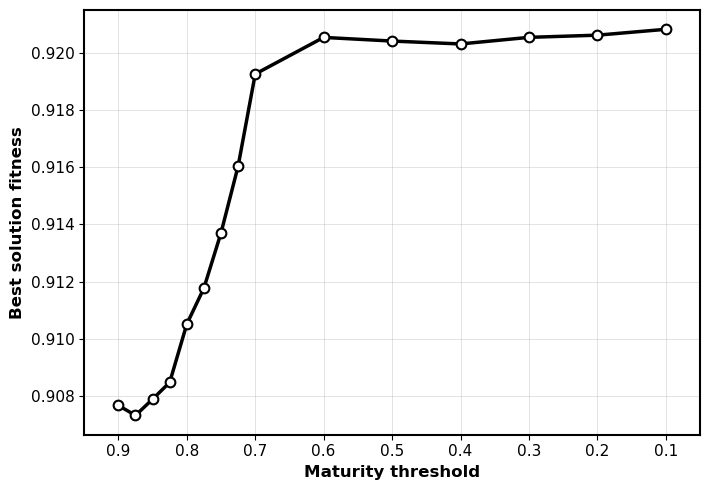

In [51]:
# Best solution fitness across maturity threshold (average across K).
fig, ax = plt.subplots(figsize=(7.2, 5.0))
for spine in ax.spines.values():
    spine.set_linewidth(1.5)
    spine.set_color('black')
ax.grid(alpha=0.5)
ax.tick_params(axis='both', labelsize=11)
y_fitness = safe_nanmean(data['breakthrough_fitness'], axis=1)
ax.plot(np.asarray(maturity_threshold_list), y_fitness, marker='o', linewidth=2.5, markersize=7, color='k',
        markerfacecolor='white', markeredgecolor='black', markeredgewidth=1.5)
ax.set_xlim(*maturity_plot_xlim)
ax.set_xticks(maturity_axis_ticks)
ax.set_xticklabels([f"{value:.1f}" for value in maturity_axis_ticks])
ax.set_xlabel('Maturity threshold', fontweight='bold', fontsize=12)
ax.set_ylabel('Best solution fitness', fontweight='bold', fontsize=12)
fig.tight_layout()
# plt.savefig(figure_folder / 'Best_solution_fitness_across_maturity_threshold.png', dpi=300, bbox_inches='tight', transparent=True)
plt.show()

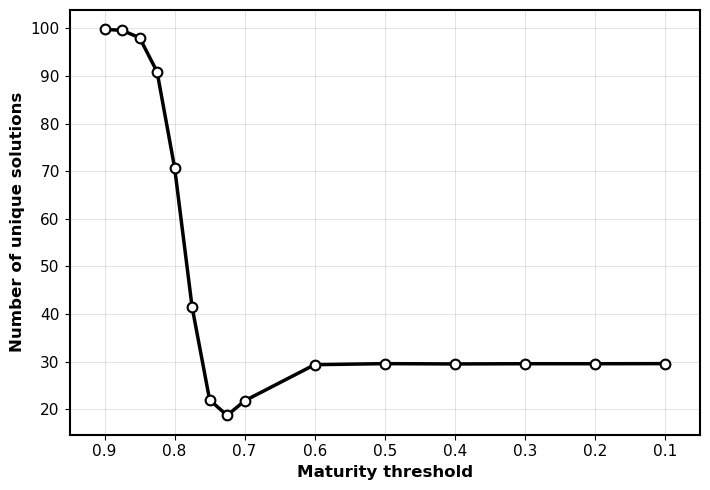

In [52]:
# Unique solution count across maturity threshold (average across K).
fig, ax = plt.subplots(figsize=(7.2, 5.0))
for spine in ax.spines.values():
    spine.set_linewidth(1.5)
    spine.set_color('black')
ax.grid(alpha=0.5)
ax.tick_params(axis='both', labelsize=11)
y_unique = safe_nanmean(data['unique_solution_count'], axis=1)
ax.plot(np.asarray(maturity_threshold_list), y_unique, marker='o', linewidth=2.5, markersize=7, color='k',
        markerfacecolor='white', markeredgecolor='black', markeredgewidth=1.5)
ax.set_xlim(*maturity_plot_xlim)
ax.set_xticks(maturity_axis_ticks)
ax.set_xticklabels([f"{value:.1f}" for value in maturity_axis_ticks])
ax.set_xlabel('Maturity threshold', fontweight='bold', fontsize=12)
ax.set_ylabel('Number of unique solutions', fontweight='bold', fontsize=12)
fig.tight_layout()
plt.savefig(figure_folder / 'Unique_solution_count_across_maturity_threshold.png', dpi=300, bbox_inches='tight', transparent=True)
plt.show()

## 5. Adoption-quality trajectories across search time

Set `trajectory_maturity_threshold` to any sampled maturity threshold. The horizontal axis gives **each visibility event** (`10, 20, ..., 300`). Values are the **cumulative mean true fitness of adopted solutions through that period**, not the average fitness of new adoptions in that period or mean fitness of all receivers. The first figure averages K values; the second plots each K separately.

In [53]:
trajectory_maturity_threshold = 0.5  # Change to any entry in maturity_threshold_list.
if trajectory_maturity_threshold not in maturity_threshold_list:
    raise ValueError('trajectory_maturity_threshold must appear in maturity_threshold_list.')
trajectory_index = maturity_threshold_list.index(trajectory_maturity_threshold)
trajectory_periods = np.arange(visibility_interval, search_iteration + 1, visibility_interval)
trajectory_by_K = data[trajectory_dv][trajectory_index]  # (K, search period)
print('Trajectory maturity threshold:', trajectory_maturity_threshold)
print('Search periods:', len(trajectory_periods), '| last search period:', trajectory_periods[-1])
print('Defined trajectory entries:', np.isfinite(trajectory_by_K).sum(), '/', trajectory_by_K.size)

Trajectory maturity threshold: 0.5
Search periods: 30 | last search period: 300
Defined trajectory entries: 270 / 270


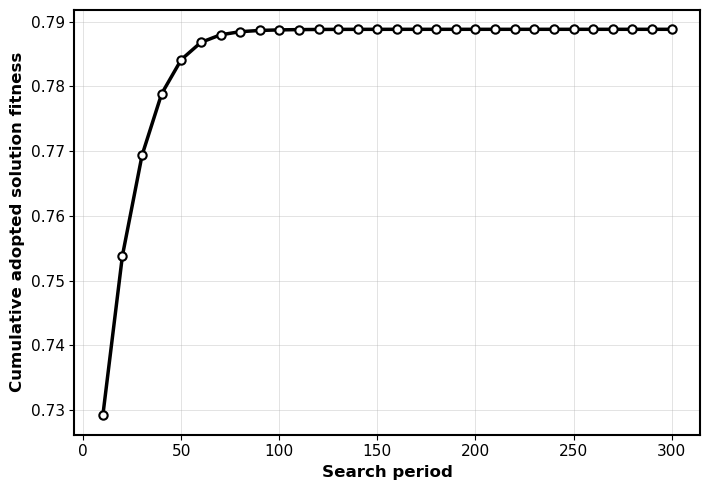

In [54]:
# Cumulative adopted solution fitness across search periods (average across K).
fig, ax = plt.subplots(figsize=(7.2, 5.0))
for spine in ax.spines.values():
    spine.set_linewidth(1.5)
    spine.set_color('black')
ax.grid(alpha=0.5)
ax.tick_params(axis='both', labelsize=11)
trajectory_mean = safe_nanmean(trajectory_by_K, axis=0)
ax.plot(trajectory_periods, trajectory_mean, marker='o', linewidth=2.5,
        markersize=6, color='k', markerfacecolor='white', markeredgecolor='black', markeredgewidth=1.5)
ax.set_xlabel('Search period', fontweight='bold', fontsize=12)
ax.set_ylabel('Cumulative adopted solution fitness', fontweight='bold', fontsize=12)
fig.tight_layout()
# plt.savefig(figure_folder / f'Adopted_solution_fitness_across_search_periods_threshold_{trajectory_maturity_threshold:g}.png', dpi=300, bbox_inches='tight', transparent=True)
plt.show()

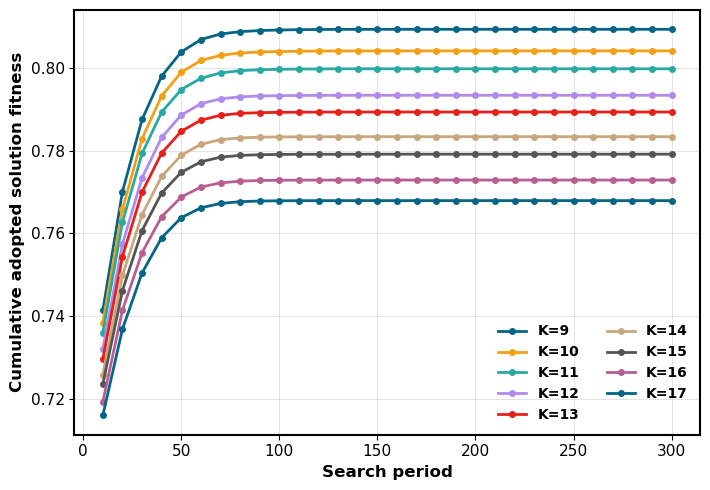

In [55]:
# Cumulative adopted solution fitness across search periods (by K).
fig, ax = plt.subplots(figsize=(7.2, 5.0))
for spine in ax.spines.values():
    spine.set_linewidth(1.5)
    spine.set_color('black')
ax.grid(alpha=0.5)
ax.tick_params(axis='both', labelsize=11)
for j, K in enumerate(K_list):
    ax.plot(trajectory_periods, trajectory_by_K[j], marker='o',
            linewidth=2.0, markersize=4, color=K_colors[j % len(K_colors)],
            label=f'K={K}')
ax.set_xlabel('Search period', fontweight='bold', fontsize=12)
ax.set_ylabel('Cumulative adopted solution fitness', fontweight='bold', fontsize=12)
ax.legend(frameon=False, ncol=2, prop={'weight': 'bold', 'size': 10})
fig.tight_layout()
# plt.savefig(figure_folder / f'Adopted_solution_fitness_by_K_across_search_periods_threshold_{trajectory_maturity_threshold:g}.png', dpi=300, bbox_inches='tight', transparent=True)
plt.show()

## 6. Maturity threshold × landscape complexity

These heatmaps display the underlying saved `(threshold, K)` averages without pooling across `K`. `NaN` cells remain blank, particularly when few or no solutions meet a stringent maturity threshold. They help diagnose whether the overall trend is stable or masks heterogeneous responses across landscape complexity.

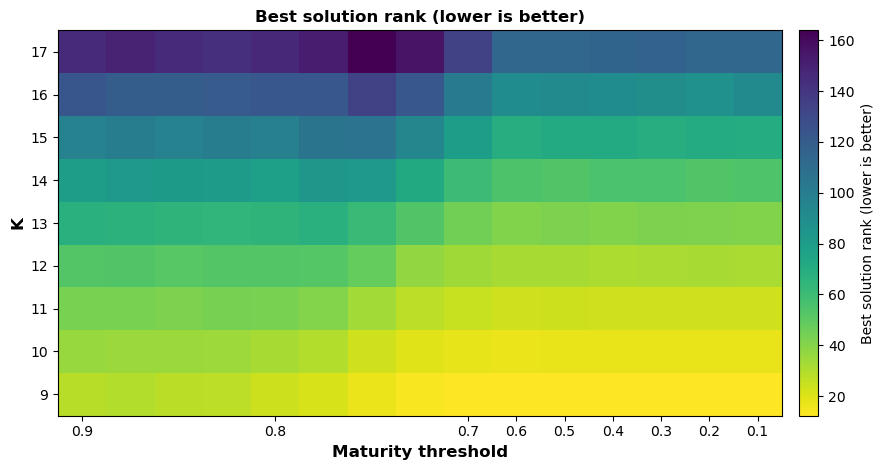

In [56]:
# Best solution rank (lower is better) across maturity threshold and K.
values = np.ma.masked_invalid(data['breakthrough_rank'].T)  # (K, threshold)
fig, ax = plt.subplots(figsize=(9.5, 4.8))
image = ax.imshow(values, aspect='auto', interpolation='nearest', cmap='viridis_r', origin='lower')
ax.set_xticks(heatmap_tick_positions)
ax.set_xticklabels(heatmap_tick_labels, rotation=0)
ax.set_yticks(np.arange(len(K_list)))
ax.set_yticklabels(K_list)
ax.invert_xaxis()  # Show the highest evaluated threshold on the left.
ax.set_xlabel('Maturity threshold', fontweight='bold', fontsize=12)
ax.set_ylabel('K', fontweight='bold', fontsize=12)
ax.set_title('Best solution rank (lower is better)', fontweight='bold', fontsize=12)
fig.colorbar(image, ax=ax, label='Best solution rank (lower is better)', pad=0.02)
fig.tight_layout()
# plt.savefig(figure_folder / 'Best_solution_rank_heatmap_across_maturity_threshold_and_K.png', dpi=300, bbox_inches='tight', transparent=True)
plt.show()


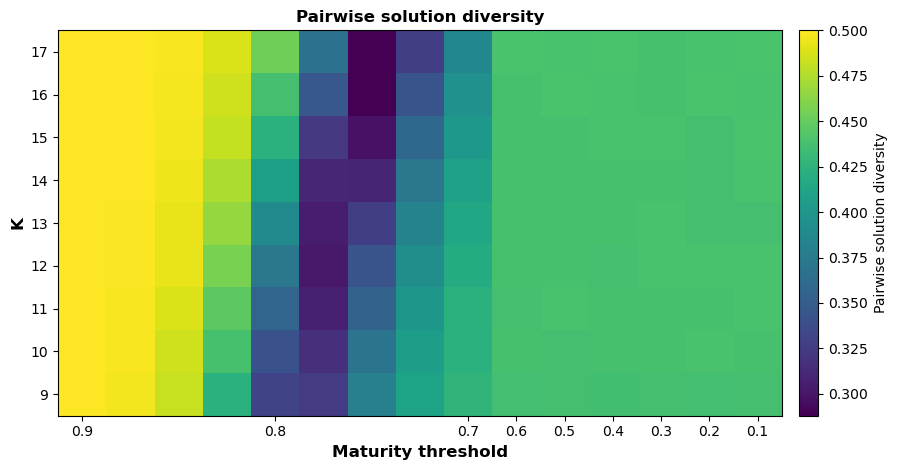

In [57]:
# Pairwise solution diversity across maturity threshold and K.
values = np.ma.masked_invalid(data['pairwise_diversity'].T)  # (K, threshold)
fig, ax = plt.subplots(figsize=(9.5, 4.8))
image = ax.imshow(values, aspect='auto', interpolation='nearest', cmap='viridis', origin='lower')
ax.set_xticks(heatmap_tick_positions)
ax.set_xticklabels(heatmap_tick_labels, rotation=0)
ax.set_yticks(np.arange(len(K_list)))
ax.set_yticklabels(K_list)
ax.invert_xaxis()  # Show the highest evaluated threshold on the left.
ax.set_xlabel('Maturity threshold', fontweight='bold', fontsize=12)
ax.set_ylabel('K', fontweight='bold', fontsize=12)
ax.set_title('Pairwise solution diversity', fontweight='bold', fontsize=12)
fig.colorbar(image, ax=ax, label='Pairwise solution diversity', pad=0.02)
fig.tight_layout()
# plt.savefig(figure_folder / 'Pairwise_diversity_heatmap_across_maturity_threshold_and_K.png', dpi=300, bbox_inches='tight', transparent=True)
plt.show()


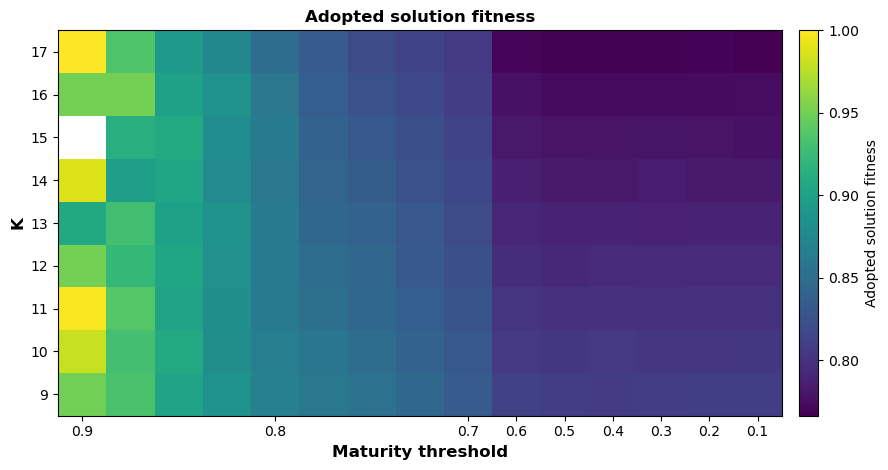

In [58]:
# Adopted solution fitness across maturity threshold and K.
values = np.ma.masked_invalid(data['adopted_solution_fitness'].T)  # (K, threshold)
fig, ax = plt.subplots(figsize=(9.5, 4.8))
image = ax.imshow(values, aspect='auto', interpolation='nearest', cmap='viridis', origin='lower')
ax.set_xticks(heatmap_tick_positions)
ax.set_xticklabels(heatmap_tick_labels, rotation=0)
ax.set_yticks(np.arange(len(K_list)))
ax.set_yticklabels(K_list)
ax.invert_xaxis()  # Show the highest evaluated threshold on the left.
ax.set_xlabel('Maturity threshold', fontweight='bold', fontsize=12)
ax.set_ylabel('K', fontweight='bold', fontsize=12)
ax.set_title('Adopted solution fitness', fontweight='bold', fontsize=12)
fig.colorbar(image, ax=ax, label='Adopted solution fitness', pad=0.02)
fig.tight_layout()
# plt.savefig(figure_folder / 'Adopted_solution_fitness_heatmap_across_maturity_threshold_and_K.png', dpi=300, bbox_inches='tight', transparent=True)
plt.show()
